# 客户生命周期价值（LTV）分析

每位真实客户（customer_unique_id）累计消费金额的分布与集中度。

客户数 93,358 | 平均 LTV 165.2 | 中位 107.8
count    93358.0
mean       165.2
std        226.3
min          0.0
25%         63.1
50%        107.8
75%        182.6
90%        318.1
95%        469.6
99%       1097.1
max      13664.1
TOP1% 客户贡献金额占比 10.3%
复购客户 LTV 均值 308.6 vs 一次性客户 160.8


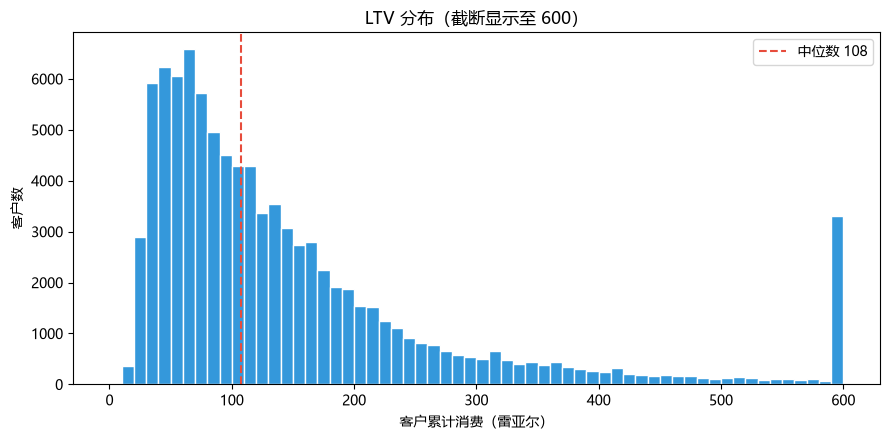

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

orders = pd.read_csv('data/orders_clean.csv', parse_dates=['order_purchase_timestamp'])
payments = pd.read_csv('data/order_payments_clean.csv')
customers = pd.read_csv('data/customers_clean.csv')

o = orders[orders['order_status'] == 'delivered'].drop_duplicates('order_id')
o['rev'] = o['order_id'].map(payments.groupby('order_id')['payment_value'].sum())
d = o.merge(customers[['customer_id', 'customer_unique_id']], on='customer_id')
ltv = d.groupby('customer_unique_id')['rev'].sum()

print(f'客户数 {len(ltv):,} | 平均 LTV {ltv.mean():.1f} | 中位 {ltv.median():.1f}')
print(ltv.describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1).to_string())
top1 = ltv.sort_values(ascending=False).head(int(len(ltv) * .01))
print('TOP1%% 客户贡献金额占比 %.1f%%' % (top1.sum() / ltv.sum() * 100))

n = d.groupby('customer_unique_id')['order_id'].nunique()
print('复购客户 LTV 均值 %.1f vs 一次性客户 %.1f' % (ltv[n > 1].mean(), ltv[n == 1].mean()))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(ltv.clip(upper=600), bins=60, color='#3498db', edgecolor='white')
ax.axvline(ltv.median(), color='#e74c3c', ls='--', label=f'中位数 {ltv.median():.0f}')
ax.set_xlabel('客户累计消费（雷亚尔）'); ax.set_ylabel('客户数')
ax.set_title('LTV 分布（截断显示至 600）'); ax.legend()
plt.tight_layout(); plt.show()


## 结论

- **LTV 整体偏低且右偏**：平均 165、中位 108，P90=318、P99=1,097，尾部极长。
- **头部集中**：TOP 1% 客户贡献 10.3% 的金额。
- **复购是最强杠杆**：复购客户 LTV 309 vs 一次性客户 161（约 1.9 倍）。在 97% 客户只买一次的结构下，提升 LTV 等价于提升复购率（详见《复购与留存》），同时对 TOP 1% 高价值客户应做会员化运营。

## 业务解读

- 中位 LTV 108 雷亚尔（≈30 美元）极低，根源是 97% 客户只买一次——LTV = 首单价值 ×（1+复购贡献），在复购率 3% 的结构下 LTV 提升的唯一路径就是复购。
- TOP 1% 贡献 10.3% 集中度尚不极端（成熟电商 TOP1% 通常 >15%），说明**超级客户群尚未形成**，头部运营是空白而非饱和。
- CAC 视角：若获客成本接近 30–50 雷亚尔（巴西行情），一次性客户的 LTV/CAC≈3–5 倍，看似健康但没算复购损失——真正的浪费是「买完即流失」。
- 与 RFM 分析联动：228 名复购客户 LTV 309，验证「复购客户价值 ≈ 2 倍一次性客户」，运营投入应按此 2 倍溢价配置。

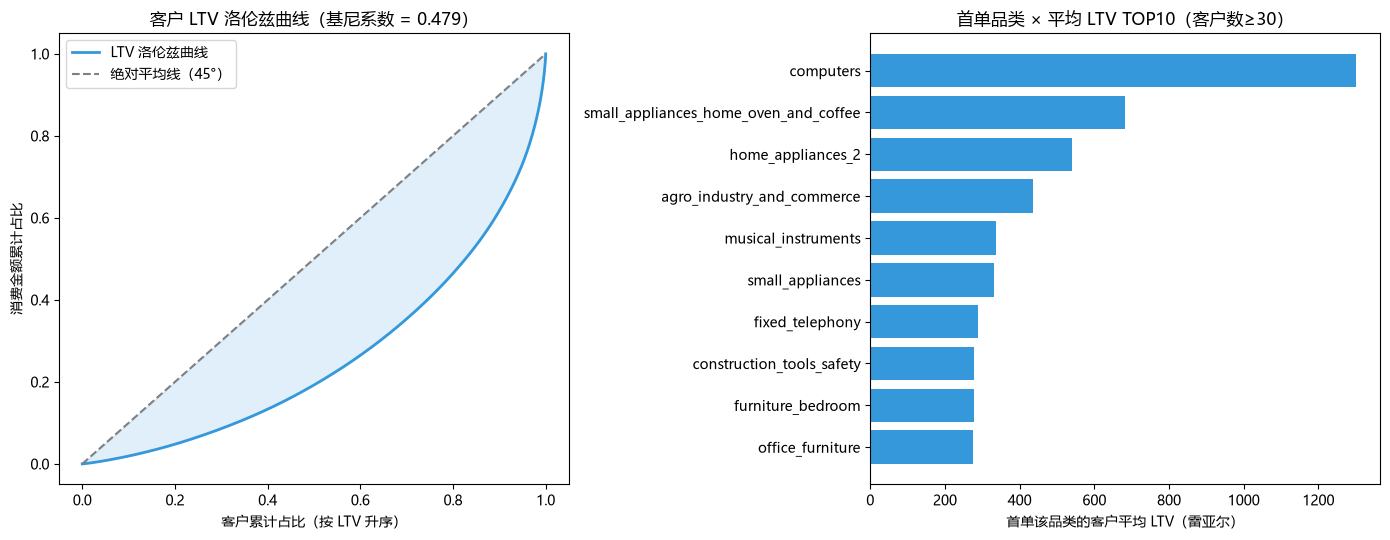

                                       mean  size
cat                                              
computers                              1300   173
small_appliances_home_oven_and_coffee   683    71
home_appliances_2                       539   216
agro_industry_and_commerce              437   174
musical_instruments                     337   596
small_appliances                        331   593
fixed_telephony                         289   207
construction_tools_safety               279   149
furniture_bedroom                       278    83
office_furniture                        274  1222


In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ① 洛伦兹曲线 + 基尼系数
v = np.sort(ltv.values)
cum_v = np.cumsum(v) / v.sum()
pop = np.arange(1, len(v) + 1) / len(v)
gini = 2 * (np.arange(1, len(v) + 1) * v).sum() / (len(v) * v.sum()) - (len(v) + 1) / len(v)
axes[0].plot(pop, cum_v, color='#3498db', lw=2, label='LTV 洛伦兹曲线')
axes[0].plot([0, 1], [0, 1], color='gray', ls='--', label='绝对平均线（45°）')
axes[0].fill_between(pop, cum_v, pop, alpha=.15, color='#3498db')
axes[0].set_xlabel('客户累计占比（按 LTV 升序）'); axes[0].set_ylabel('消费金额累计占比')
axes[0].set_title(f'客户 LTV 洛伦兹曲线（基尼系数 = {gini:.3f}）')
axes[0].legend(loc='upper left')

# ② 首单品类 × 平均 LTV（TOP10，客户数≥30）
items_ = pd.read_csv('data/order_items_clean.csv')
products_ = pd.read_csv('data/products_clean.csv')
cat_of_order = (items_.merge(products_[['product_id', 'product_category_name_english']], on='product_id')
                .drop_duplicates('order_id').set_index('order_id')['product_category_name_english'])
first_order = d.sort_values('order_purchase_timestamp').drop_duplicates('customer_unique_id').copy()
first_order['cat'] = first_order['order_id'].map(cat_of_order)
first_order['ltv'] = first_order['customer_unique_id'].map(ltv)
seg = first_order.groupby('cat')['ltv'].agg(['mean', 'size'])
seg = seg[seg['size'] >= 30].sort_values('mean', ascending=False).head(10)
axes[1].barh(seg.index[::-1], seg['mean'][::-1], color='#3498db')
axes[1].set_xlabel('首单该品类的客户平均 LTV（雷亚尔）')
axes[1].set_title('首单品类 × 平均 LTV TOP10（客户数≥30）')

plt.tight_layout()
plt.show()
print(seg.round(0).astype(int).to_string())